# RoadScan: real inference with the adopted run-17 model

Version 2 verifies the unchanged detector module against **run17_best_finetuned.pt**, the team-adopted project model. Version 1 tested the original published candidate and remains historical. Run 17 fine-tuned the published initialization on 8,999 team images. Adoption reflects the team decision, not a claim of outperforming the original. No training or final local test is performed here.


## 1. Load the adopted fine-tuned detector

Write the exact GitHub detector module, install the recorded Ultralytics version, verify run-17 checkpoint SHA-256, and load it once on CPU.


In [1]:
from pathlib import Path
import sys, subprocess, hashlib, json, urllib.request, math
from collections import Counter
from IPython.display import display, Markdown
subprocess.check_call([sys.executable,'-m','pip','install','-q','ultralytics==8.4.177'])
OUT=Path('/kaggle/working/inference_smoke'); OUT.mkdir(exist_ok=True)
module_source='"""Single-image YOLO inference returning RDD2022 D codes and pixel boxes."""\nfrom pathlib import Path\nimport math\n\n_NAME_TO_CODE = {\n    \'d00\': \'D00\', \'longitudinal_crack\': \'D00\',\n    \'d10\': \'D10\', \'transverse_crack\': \'D10\',\n    \'d20\': \'D20\', \'alligator_crack\': \'D20\',\n    \'d40\': \'D40\', \'pothole\': \'D40\',\n}\n\n\nclass RoadDamageDetector:\n    """Load a local four-class checkpoint once, then call detect_damage(image).\n\n    image: a local image path, PIL image, or OpenCV BGR numpy array.\n    Output: JSON-compatible detections; bbox_xyxy is in original-image pixels.\n    An empty list means no detection above the threshold, not a verified safe road.\n    """\n\n    def __init__(self, weights, *, device=\'cpu\', imgsz=640):\n        weights = Path(weights)\n        if not weights.is_file():\n            raise FileNotFoundError(f\'Checkpoint not found: {weights}\')\n        if not isinstance(imgsz, int) or isinstance(imgsz, bool) or imgsz <= 0:\n            raise ValueError(\'imgsz must be a positive integer.\')\n        from ultralytics import YOLO\n        self._model = YOLO(str(weights))\n        self.device = device\n        self.imgsz = imgsz\n        names = self._model.names\n        names = dict(enumerate(names)) if isinstance(names, (list, tuple)) else names\n        try:\n            self._codes = {int(i): _NAME_TO_CODE[str(name).strip().lower()]\n                           for i, name in names.items()}\n        except (KeyError, TypeError, ValueError) as exc:\n            raise ValueError(\'Expected D00/D10/D20/D40 or the published semantic class names; incompatible checkpoint.\') from exc\n        if len(self._codes) != 4 or set(self._codes.values()) != {\'D00\', \'D10\', \'D20\', \'D40\'}:\n            raise ValueError(\'Checkpoint must contain each of the four RDD2022 damage classes exactly once.\')\n\n    def detect_damage(self, image, *, confidence=0.25, iou=0.7):\n        """Return every retained damage as damage_code, bbox_xyxy, confidence.\n\n        confidence=0.25 is provisional, not a validated deployment threshold.\n        Invalid/unreadable images raise an exception, rather than returning [].\n        """\n        for name, value in [(\'confidence\', confidence), (\'iou\', iou)]:\n            if not isinstance(value, (int, float)) or not math.isfinite(value) or not 0 <= value <= 1:\n                raise ValueError(f\'{name} must be between 0 and 1.\')\n        if image is None or isinstance(image, (list, tuple, int, float)):\n            raise TypeError(\'Pass one local image path, PIL image, or OpenCV BGR numpy array.\')\n        if isinstance(image, (str, Path)):\n            from PIL import Image\n            with Image.open(image) as opened:\n                image = opened.convert(\'RGB\')\n        else:\n            # PIL images use RGB; numpy input follows Ultralytics OpenCV BGR convention.\n            from PIL import Image\n            import numpy as np\n            if isinstance(image, Image.Image):\n                image = image.convert(\'RGB\')\n            elif not isinstance(image, np.ndarray) or image.ndim != 3 or image.shape[2] != 3 or image.size == 0:\n                raise TypeError(\'Array input must be a nonempty H x W x 3 BGR image.\')\n        results = self._model.predict(source=image, imgsz=self.imgsz,\n                                      conf=confidence, iou=iou, max_det=300,\n                                      device=self.device, verbose=False)\n        if len(results) != 1:\n            raise ValueError(\'Expected exactly one image result.\')\n        boxes = results[0].boxes\n        if boxes is None:\n            return []\n        detections = []\n        for xyxy, cls_id, score in zip(boxes.xyxy.cpu().tolist(),\n                                       boxes.cls.cpu().tolist(),\n                                       boxes.conf.cpu().tolist()):\n            detections.append({\n                \'damage_code\': self._codes[int(cls_id)],\n                \'bbox_xyxy\': [float(v) for v in xyxy],\n                \'confidence\': float(score),\n            })\n        return detections\n'
assert hashlib.sha256(module_source.encode()).hexdigest() == '5e41fe3cbfc0b665e99f66a5f33c587b4396902b15d8151f57aed54b0d7cd103'
Path('/kaggle/working/roadscan_detector.py').write_text(module_source)
sys.path.insert(0,'/kaggle/working')
from roadscan_detector import RoadDamageDetector
BASE=Path('/kaggle/input/notebooks/rimasabunasser/17-roadscan-gentle-finetuning')
WEIGHTS=BASE/'run17_model_comparison/run17_best_finetuned.pt'
assert WEIGHTS.is_file(), 'Attach run 17 Version 1 output.'
weight_sha=hashlib.sha256(WEIGHTS.read_bytes()).hexdigest()
assert weight_sha=='25b412ff18c05e2607f4bc61b872f39826e8d53ffdc7647654c1f419e355d15f'
import torch
torch.set_num_threads(2)
detector=RoadDamageDetector(WEIGHTS,device='cpu')
detect_damage=detector.detect_damage
print('REAL_CHECKPOINT_READY',weight_sha)
display(Markdown('**Setup result.** The detector module matches the GitHub implementation byte for byte. The fine-tuned checkpoint matches the saved run-17 SHA-256. This is the team-adopted project model; the original published checkpoint is only a reference. It is loaded on CPU without training.'))


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 20.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.1/99.1 kB 3.7 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
REAL_CHECKPOINT_READY 25b412ff18c05e2607f4bc61b872f39826e8d53ffdc7647654c1f419e355d15f


**Setup result.** The detector module matches the GitHub implementation byte for byte. The fine-tuned checkpoint matches the saved run-17 SHA-256. This is the team-adopted project model; the original published checkpoint is only a reference. It is loaded on CPU without training.

## 2. Check real detections

Choose a small deterministic set of China development images containing the four ground-truth classes. Check actual D codes, box coordinates and confidences; compare supported input types; record a blank-image prediction; save JSON and annotated examples. This is a functional integration test, not a performance benchmark.

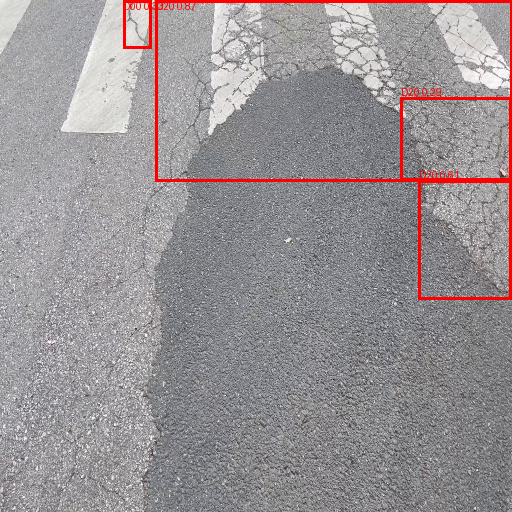

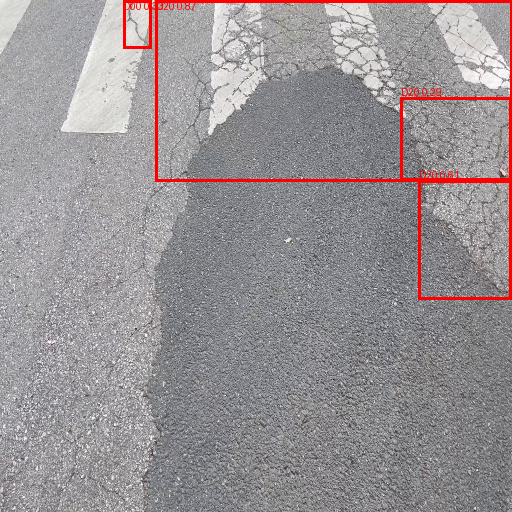

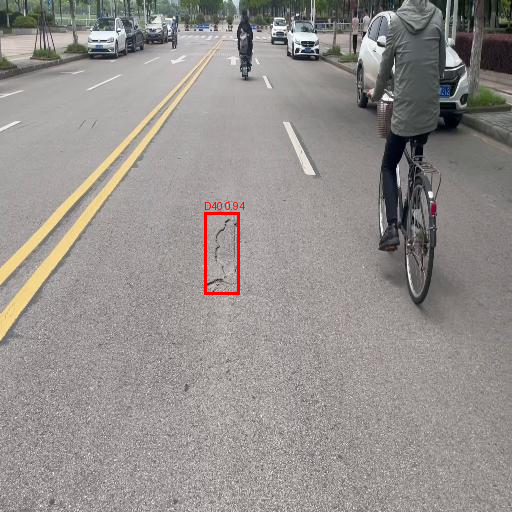

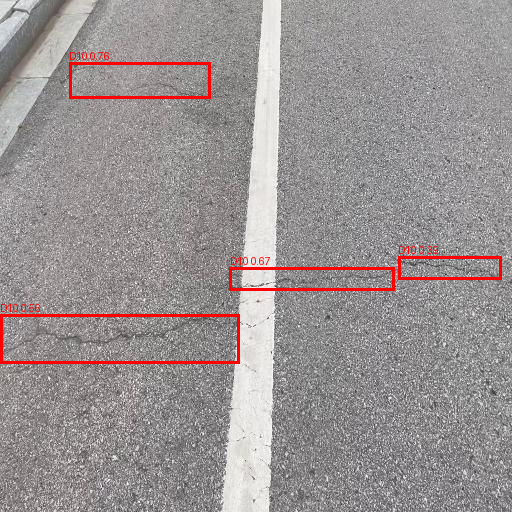

REAL_INFERENCE_SMOKE_PASSED {"status": "passed", "module_sha256": "5e41fe3cbfc0b665e99f66a5f33c587b4396902b15d8151f57aed54b0d7cd103", "checkpoint_sha256": "25b412ff18c05e2607f4bc61b872f39826e8d53ffdc7647654c1f419e355d15f", "checkpoint": "run17_best_finetuned.pt; team-adopted fine-tuned project model", "device": "cpu", "images": 15, "detections": 44, "codes_observed": ["D00", "D10", "D20", "D40"], "counts": {"D20": 10, "D00": 15, "D40": 6, "D10": 13}, "examples": {"D20": {"image": "China_MotorBike_000000.jpg", "damage_code": "D20", "bbox_xyxy": [155.7138671875, 0.793896496295929, 512.0, 181.85850524902344], "confidence": 0.8686223030090332}, "D00": {"image": "China_MotorBike_000000.jpg", "damage_code": "D00", "bbox_xyxy": [123.2349624633789, 0.0, 151.06201171875, 48.17469787597656], "confidence": 0.3332657516002655}, "D40": {"image": "China_MotorBike_000001.jpg", "damage_code": "D40", "bbox_xyxy": [204.02664184570312, 212.4994659423828, 239.8946990966797, 294.887451171875], "confidence"

**Results interpretation.** The actual checkpoint processed **15 development images** and returned **44 detections**. All four codes D00/D10/D20/D40 appeared with valid pixel boxes and confidence values. Local paths, PIL RGB and OpenCV BGR inputs worked. The blank-image check returned 0 detections. These are implementation checks, not independent accuracy estimates or proof of Saudi-road generalization. Full outputs are saved in `inference_smoke/inference_smoke_results.json`.

In [2]:
from PIL import Image, ImageDraw
import numpy as np
DATA=BASE/'run17_team_v2_data/val'
assert DATA.is_dir(), 'Attach run 17 version 1 saved output.'
selected=[]; covered={i:0 for i in range(4)}
for label in sorted((DATA/'labels').glob('*.txt')):
    ids={int(line.split()[0]) for line in label.read_text().splitlines() if line.strip()}
    if any(covered[i]<5 for i in ids):
        selected.append(DATA/'images'/(label.stem+'.jpg'))
        for i in ids: covered[i]+=1
    if all(v>=5 for v in covered.values()): break
assert selected and len(selected)<=20
rows=[]; counts=Counter(); examples={}
for path in selected:
    with Image.open(path) as image: width,height=image.size
    detections=detect_damage(path,confidence=0.25)
    for box in detections:
        assert set(box)=={'damage_code','bbox_xyxy','confidence'}
        assert box['damage_code'] in {'D00','D10','D20','D40'}
        assert 0.25<=box['confidence']<=1
        x1,y1,x2,y2=box['bbox_xyxy']
        assert all(math.isfinite(v) for v in box['bbox_xyxy'])
        assert 0<=x1<x2<=width and 0<=y1<y2<=height
        counts[box['damage_code']]+=1
        examples.setdefault(box['damage_code'],dict(image=path.name,**box))
    rows.append(dict(image=path.name,detections=detections))
assert set(counts)=={'D00','D10','D20','D40'}, dict(counts)
# Check local-path, PIL RGB and OpenCV BGR input routes using one real image.
with Image.open(selected[0]) as opened: rgb=opened.convert('RGB')
via_pil=detect_damage(rgb)
via_bgr=detect_damage(np.asarray(rgb)[:,:,::-1].copy())
assert [x['damage_code'] for x in via_pil]==[x['damage_code'] for x in rows[0]['detections']]
assert len(via_bgr)==len(via_pil)
for left,right in zip(via_pil,via_bgr):
    assert left['damage_code']==right['damage_code']
    assert np.allclose(left['bbox_xyxy'],right['bbox_xyxy'],atol=0.1)
    assert abs(left['confidence']-right['confidence'])<0.001
blank=detect_damage(Image.new('RGB',(640,640),'white'))
# This proves schema behavior on actual output; blank-image detections, if any,
# are recorded as model false alarms rather than concealed.
result=dict(status='passed',module_sha256=hashlib.sha256(module_source.encode()).hexdigest(),checkpoint_sha256=weight_sha,checkpoint='run17_best_finetuned.pt; team-adopted fine-tuned project model',device='cpu',images=len(rows),detections=sum(counts.values()),codes_observed=sorted(counts),counts=dict(counts),examples=examples,input_routes_verified=['local_path','PIL_RGB','numpy_BGR'],blank_image_detections=blank,predictions=rows,scope='software integration smoke test on development images; not an accuracy or generalization benchmark',no_training=True,personal_photos_used=False)
(OUT/'inference_smoke_results.json').write_text(json.dumps(result,indent=2))
for code_name,example in examples.items():
    canvas=Image.open(DATA/'images'/example['image']).convert('RGB');draw=ImageDraw.Draw(canvas)
    for box in next(r['detections'] for r in rows if r['image']==example['image']):
        draw.rectangle(box['bbox_xyxy'],outline='red',width=3)
        draw.text((box['bbox_xyxy'][0],max(0,box['bbox_xyxy'][1]-12)),f"{box['damage_code']} {box['confidence']:.2f}",fill='red')
    canvas.save(OUT/f'{code_name}_example.jpg')
    display(canvas)
print('REAL_INFERENCE_SMOKE_PASSED',json.dumps({k:v for k,v in result.items() if k not in ['predictions','blank_image_detections']}))
display(Markdown(f'**Results interpretation.** The actual checkpoint processed **{len(rows)} development images** and returned **{sum(counts.values())} detections**. All four codes D00/D10/D20/D40 appeared with valid pixel boxes and confidence values. Local paths, PIL RGB and OpenCV BGR inputs worked. The blank-image check returned {len(blank)} detections. These are implementation checks, not independent accuracy estimates or proof of Saudi-road generalization. Full outputs are saved in `inference_smoke/inference_smoke_results.json`.'))
